In [9]:
import numpy as np

# ── Paths ─────────────────────────────────────────────────────────────────────
HW_NAS_ROOT     = r"C:\Users\hp\Desktop\ETUDES\S2\Projet\Code\hwnas-with-metaheuristics-project\HW-NAS-Bench"
HW_NAS_PICKLE   = f"{HW_NAS_ROOT}/HW-NAS-Bench-v1_0.pickle"
# NAS201_ROOT     = r"C:\Users\hp\Desktop\ETUDES\S2\Projet\Code\hwnas-with-metaheuristics-project\nas-bench-201"
ACC_CSV         = r"C:\Users\hp\Desktop\ETUDES\S2\Projet\Code\hwnas-with-metaheuristics-project\data\nasbench201_accuracies.csv"
EXHAUSTIVE_ROOT = r"C:\Users\hp\Desktop\ETUDES\S2\Projet\Code\hwnas-with-metaheuristics-project/results/Results"
OUTPUT_ROOT     = r"C:\Users\hp\Desktop\ETUDES\S2\Projet\Code\hwnas-with-metaheuristics-project/working/enhanced_mo_re"

# ── Search grid ───────────────────────────────────────────────────────────────
DATASETS  = ["cifar10", "cifar100", "ImageNet16-120"]
PLATFORMS = ["edgegpu", "raspi4", "pixel3", "fpga"]

# ── Shared evolution parameters ───────────────────────────────────────────────
POPULATION_SIZE = 50
NUM_CYCLES      = 200
NUM_RUNS        = 5
SEED            = 42

# Fixed tournament size (used by MO-RE baseline and MO-RE+CD+HWM)
TOURNAMENT_SIZE = 10

# Adaptive S range (used by MO-RE+AdaS only)
S_MIN = 3
S_MAX = 12

SEARCH_SPACE_SIZE = 15_625

np.random.seed(SEED)
print(f"Grid: {len(DATASETS)} datasets × {len(PLATFORMS)} platforms = {len(DATASETS)*len(PLATFORMS)} combinations")
print(f"Variants: MO-RE | MO-RE+CD+HWM | MO-RE+AdaS")

Grid: 3 datasets × 4 platforms = 12 combinations
Variants: MO-RE | MO-RE+CD+HWM | MO-RE+AdaS


In [10]:
import sys, os, collections
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, HW_NAS_ROOT)
sys.path.insert(0, NAS201_ROOT)


from hw_nas_bench_api import HWNASBenchAPI as HWAPI

hw_api = HWAPI(HW_NAS_PICKLE, search_space="nasbench201")
acc_df = pd.read_csv(ACC_CSV).set_index("arch_index")

os.makedirs(OUTPUT_ROOT, exist_ok=True)

print("Benchmarks loaded.")

Benchmarks loaded.


# NSGA-II — Multi-Objective NAS
**Objective**: Maximize accuracy · Minimize latency  
**Search space**: NAS-Bench-201 (15 625 architectures) via HW-NAS-Bench  
**Algorithm**: NSGA-II (Non-dominated Sorting Genetic Algorithm II)  
**Reference baseline**: Exhaustive Pareto front (true optimal)

## 0 · Configuration

In [11]:
import numpy as np


# ── Search config ─────────────────────────────────────────────────────────────
DATASET       = "cifar10"      # cifar10 | cifar100 | ImageNet16-120
HW_PLATFORM   = "raspi4"       # edgegpu | raspi4 | edgetpu | pixel3 | eyeriss | fpga
SEED          = 42

SEARCH_SPACE_SIZE = 15_625     # do NOT change

# ── NSGA-II hyper-parameters ──────────────────────────────────────────────────
POP_SIZE      = 100            # population size (must be even)
N_GENERATIONS = 50             # number of generations
CROSSOVER_PROB = 0.9           # crossover probability
MUTATION_PROB  = 0.1           # mutation probability (per individual)
TOURNAMENT_K   = 2             # tournament selection size

np.random.seed(SEED)
print(f"Config: dataset={DATASET}, hw_platform={HW_PLATFORM}, seed={SEED}")
print(f"NSGA-II: pop={POP_SIZE}, generations={N_GENERATIONS}")

Config: dataset=cifar10, hw_platform=raspi4, seed=42
NSGA-II: pop=100, generations=50


## 1 · Setup & imports

In [12]:
import sys, os, time
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from tqdm import tqdm

sys.path.insert(0, HW_NAS_ROOT)
sys.path.insert(0, NAS201_ROOT)

plt.style.use("seaborn-v0_8-whitegrid")

print("Python", sys.version)
print("NumPy ", np.__version__)
print("Pandas", pd.__version__)

Python 3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 16:37:03) [MSC v.1929 64 bit (AMD64)]
NumPy  2.1.3
Pandas 2.2.3


## 2 · Load HW-NAS-Bench (hardware metrics)

In [13]:
from hw_nas_bench_api import HWNASBenchAPI as HWAPI

hw_api = HWAPI(HW_NAS_PICKLE, search_space="nasbench201")

LATENCY_KEY = f"{HW_PLATFORM}_latency"

sample = hw_api.query_by_index(0, DATASET)
print("Available HW keys:", list(sample.keys()))
assert LATENCY_KEY in sample, (
    f"Key '{LATENCY_KEY}' not found. Available: {list(sample.keys())}"
)
print(f"Latency key used : '{LATENCY_KEY}'")
print(f"Sample latency   : {sample[LATENCY_KEY]:.4f} ms")

Available HW keys: ['edgegpu_latency', 'edgegpu_energy', 'raspi4_latency', 'edgetpu_latency', 'pixel3_latency', 'eyeriss_latency', 'eyeriss_energy', 'eyeriss_arithmetic_intensity', 'fpga_latency', 'fpga_energy', 'average_hw_metric']
Latency key used : 'raspi4_latency'
Sample latency   : 10.4820 ms


## 3 · Load accuracy lookup (pre-extracted CSV)

In [14]:
acc_df = pd.read_csv(ACC_CSV).set_index("arch_index")

ACC_COL = f"acc_{DATASET}"
assert ACC_COL in acc_df.columns, (
    f"Column '{ACC_COL}' not found. Available: {list(acc_df.columns)}"
)

print(f"Accuracy table : {acc_df.shape[0]} architectures × {acc_df.shape[1]} datasets")
print(acc_df.head())


def get_accuracy(arch_index: int) -> float:
    """Returns test accuracy (%) for the configured dataset."""
    return float(acc_df.loc[arch_index, ACC_COL])


def get_latency(arch_index: int) -> float:
    """Returns latency (ms) for the configured platform and dataset."""
    return float(hw_api.query_by_index(arch_index, DATASET)[LATENCY_KEY])


def evaluate(arch_index: int):
    """Returns (accuracy, latency) for a given architecture index."""
    return get_accuracy(arch_index), get_latency(arch_index)


print(f"\nArch 0 — accuracy: {get_accuracy(0):.2f}%  latency: {get_latency(0):.4f} ms")

Accuracy table : 15625 architectures × 3 datasets
            acc_cifar10  acc_cifar100  acc_ImageNet16-120
arch_index                                               
0                 81.90         51.98           25.766667
1                 90.63         69.68           45.433333
2                 81.93         55.24           26.700000
3                 83.78         58.22           28.133333
4                 84.44         59.98           31.200000

Arch 0 — accuracy: 81.90%  latency: 10.4820 ms


## 4 · Exhaustive Pareto front (true reference)

In [15]:
print("Building exhaustive evaluation table (used as ground-truth Pareto front)...")
start = time.time()

all_results = []
for idx in tqdm(range(SEARCH_SPACE_SIZE), desc="Exhaustive scan"):
    acc, lat = evaluate(idx)
    all_results.append({"arch_index": idx, "accuracy": acc, "latency": lat})

df_all = pd.DataFrame(all_results)
print(f"Done in {time.time()-start:.2f}s")
print(f"Accuracy  : {df_all['accuracy'].min():.2f}% – {df_all['accuracy'].max():.2f}%")
print(f"Latency   : {df_all['latency'].min():.4f} – {df_all['latency'].max():.4f} ms")

Building exhaustive evaluation table (used as ground-truth Pareto front)...


Exhaustive scan: 100%|██████████| 15625/15625 [00:00<00:00, 42921.29it/s]

Done in 0.42s
Accuracy  : 10.00% – 91.49%
Latency   : 0.0113 – 98.8875 ms


## 5 · Shared utility functions

In [16]:
def is_pareto_front(acc_arr, lat_arr):
    """
    Returns a boolean mask of Pareto-optimal solutions.
    Objectives: maximize accuracy, minimize latency.
    """
    n = len(acc_arr)
    mask = np.ones(n, dtype=bool)
    for i in range(n):
        if not mask[i]:
            continue
        dominated = (
            (acc_arr >= acc_arr[i]) & (lat_arr <= lat_arr[i]) &
            ((acc_arr > acc_arr[i]) | (lat_arr < lat_arr[i]))
        )
        dominated[i] = False
        if dominated.any():
            mask[i] = False
    return mask


def compute_pareto_df(df: pd.DataFrame) -> pd.DataFrame:
    mask = is_pareto_front(df["accuracy"].values, df["latency"].values)
    return df[mask].sort_values("accuracy", ascending=False).reset_index(drop=True)


def hypervolume_2d(pareto_df: pd.DataFrame, ref_point: tuple) -> float:
    """
    2-D hypervolume indicator.
    ref_point = (ref_latency, ref_accuracy) — must be worse than every Pareto point.
    """
    ref_lat, ref_acc = ref_point
    pts = pareto_df.sort_values("latency")[["accuracy", "latency"]].values
    hv = 0.0
    prev_lat = 0.0
    for acc, lat in pts:
        if lat >= ref_lat:
            break
        hv += (ref_acc - acc) * (lat - prev_lat)
        prev_lat = lat
    # remaining width up to ref
    hv = 0.0
    pts_sorted = pareto_df.sort_values("latency")[["accuracy", "latency"]].values
    prev_lat = 0.0
    for acc, lat in pts_sorted:
        width = lat - prev_lat
        height = acc - ref_acc if acc > ref_acc else 0.0
        hv += width * height
        prev_lat = lat
    return hv


# True Pareto front (exhaustive)
true_pareto = compute_pareto_df(df_all)
print(f"True Pareto front size: {len(true_pareto)} / {SEARCH_SPACE_SIZE}")
print(f"Best accuracy : {true_pareto['accuracy'].max():.2f}%")
print(f"Best latency  : {true_pareto['latency'].min():.4f} ms")

True Pareto front size: 43 / 15625
Best accuracy : 91.49%
Best latency  : 0.0113 ms


## 6 · NSGA-II implementation

Each individual is an **integer in [0, 15624]** — its index in the NAS-Bench-201 / HW-NAS-Bench lookup tables.  
No architecture is trained: both objectives are **instant lookups** (CSV + pickle), exactly as in the baseline.

### Algorithm outline
1. **Initialise** a random population of size `POP_SIZE`.
2. **Evaluate** each individual → (accuracy, latency).
3. **Non-dominated sort** → assign Pareto rank.
4. **Crowding distance** → secondary sorting criterion within a rank.
5. **Tournament selection** + **one-point crossover** + **mutation** → offspring.
6. **Combine** parent + offspring, repeat sort → keep best `POP_SIZE` individuals.
7. Repeat for `N_GENERATIONS`.

In [17]:
# ─────────────────────────────────────────────────────────────────────────────
#  NSGA-II core components
# ─────────────────────────────────────────────────────────────────────────────

def fast_non_dominated_sort(objectives):
    """
    objectives : ndarray of shape (n, 2) — [accuracy, latency]
    Returns list of fronts (each front is a list of indices).
    Objective 0 (accuracy) is maximised; objective 1 (latency) is minimised.
    """
    n = len(objectives)
    acc = objectives[:, 0]
    lat = objectives[:, 1]

    dom_count  = np.zeros(n, dtype=int)   # how many solutions dominate i
    dom_set    = [[] for _ in range(n)]   # solutions dominated by i

    for i in range(n):
        for j in range(n):
            if i == j:
                continue
            # j dominates i if j is at least as good on both and strictly better on one
            if (acc[j] >= acc[i] and lat[j] <= lat[i] and
                    (acc[j] > acc[i] or lat[j] < lat[i])):
                dom_count[i] += 1
            elif (acc[i] >= acc[j] and lat[i] <= lat[j] and
                    (acc[i] > acc[j] or lat[i] < lat[j])):
                dom_set[i].append(j)

    fronts = []
    current_front = [i for i in range(n) if dom_count[i] == 0]
    while current_front:
        fronts.append(current_front)
        next_front = []
        for i in current_front:
            for j in dom_set[i]:
                dom_count[j] -= 1
                if dom_count[j] == 0:
                    next_front.append(j)
        current_front = next_front

    return fronts


def crowding_distance(objectives, front):
    """
    Returns crowding distances for individuals in `front`.
    objectives : ndarray (n, 2)
    front      : list of indices into objectives
    """
    size = len(front)
    distances = np.zeros(size)
    if size <= 2:
        distances[:] = np.inf
        return distances

    for m in range(objectives.shape[1]):
        vals   = objectives[front, m]
        order  = np.argsort(vals)
        f_min  = vals[order[0]]
        f_max  = vals[order[-1]]
        spread = f_max - f_min if f_max != f_min else 1e-8

        distances[order[0]]  = np.inf
        distances[order[-1]] = np.inf
        for k in range(1, size - 1):
            distances[order[k]] += (vals[order[k+1]] - vals[order[k-1]]) / spread

    return distances


def tournament_select(pop, ranks, cd, k=2):
    """Binary (or k-way) tournament selection — returns one winner index."""
    candidates = np.random.choice(len(pop), k, replace=False)
    best = candidates[0]
    for c in candidates[1:]:
        if ranks[c] < ranks[best]:
            best = c
        elif ranks[c] == ranks[best] and cd[c] > cd[best]:
            best = c
    return best


def crossover(p1, p2):
    """
    Uniform crossover between two arch indices.
    Since each individual is a single integer (the arch index), we implement
    'bit-level' crossover on the 14-bit binary representation (2^14 = 16384 < 15625).
    """
    if np.random.rand() > CROSSOVER_PROB:
        return p1, p2
    # Treat the index as a 14-bit string and do single-point crossover
    bits = 14
    point = np.random.randint(1, bits)
    mask  = (1 << point) - 1
    c1 = ((p1 & ~mask) | (p2 & mask)) % SEARCH_SPACE_SIZE
    c2 = ((p2 & ~mask) | (p1 & mask)) % SEARCH_SPACE_SIZE
    return int(c1), int(c2)


def mutate(ind):
    """Flip a random bit in the 14-bit representation."""
    if np.random.rand() > MUTATION_PROB:
        return ind
    bit = np.random.randint(0, 14)
    return int(ind ^ (1 << bit)) % SEARCH_SPACE_SIZE


print("NSGA-II components defined.")

NSGA-II components defined.


## 7 · Run NSGA-II

In [18]:
np.random.seed(SEED)

# ── Caches (avoid redundant lookups) ─────────────────────────────────────────
eval_cache = {}  # arch_index -> (accuracy, latency)

def cached_evaluate(idx):
    if idx not in eval_cache:
        eval_cache[idx] = evaluate(idx)
    return eval_cache[idx]

# ── Initialise population ─────────────────────────────────────────────────────
population = list(np.random.choice(SEARCH_SPACE_SIZE, POP_SIZE, replace=False))

history = []   # track Pareto front size per generation

start_time = time.time()

for gen in tqdm(range(N_GENERATIONS), desc="NSGA-II generations"):

    # ── Evaluate ──────────────────────────────────────────────────────────────
    obj = np.array([cached_evaluate(ind) for ind in population])  # (POP, 2)
    # obj[:,0] = accuracy (maximise), obj[:,1] = latency (minimise)

    # ── Non-dominated sort ────────────────────────────────────────────────────
    fronts = fast_non_dominated_sort(obj)

    # Assign rank and crowding distance to every individual
    ranks = np.empty(len(population), dtype=int)
    cd    = np.zeros(len(population))
    for rank_idx, front in enumerate(fronts):
        for i in front:
            ranks[i] = rank_idx
        cd_vals = crowding_distance(obj, front)
        for k, i in enumerate(front):
            cd[i] = cd_vals[k]

    # ── Generate offspring ────────────────────────────────────────────────────
    offspring = []
    while len(offspring) < POP_SIZE:
        p1 = population[tournament_select(population, ranks, cd, TOURNAMENT_K)]
        p2 = population[tournament_select(population, ranks, cd, TOURNAMENT_K)]
        c1, c2 = crossover(p1, p2)
        offspring.append(mutate(c1))
        if len(offspring) < POP_SIZE:
            offspring.append(mutate(c2))

    # ── Combine & select next generation ─────────────────────────────────────
    combined      = population + offspring                  # 2 * POP_SIZE
    obj_combined  = np.array([cached_evaluate(ind) for ind in combined])
    fronts_c      = fast_non_dominated_sort(obj_combined)

    new_pop  = []
    new_objs = []
    for front in fronts_c:
        if len(new_pop) + len(front) <= POP_SIZE:
            new_pop  += [combined[i] for i in front]
            new_objs += [obj_combined[i] for i in front]
        else:
            # Fill remaining slots by crowding distance (descending)
            needed = POP_SIZE - len(new_pop)
            cd_front = crowding_distance(obj_combined, front)
            sorted_by_cd = sorted(range(len(front)), key=lambda k: -cd_front[k])
            for k in sorted_by_cd[:needed]:
                new_pop.append(combined[front[k]])
            break

    population = new_pop

    # ── Log ───────────────────────────────────────────────────────────────────
    pf_mask = is_pareto_front(
        np.array([cached_evaluate(i)[0] for i in population]),
        np.array([cached_evaluate(i)[1] for i in population])
    )
    history.append({"generation": gen + 1, "pareto_front_size": int(pf_mask.sum())})

elapsed = time.time() - start_time
total_evals = len(eval_cache)

print(f"\nNSGA-II finished in {elapsed:.2f}s")
print(f"Total unique architectures evaluated: {total_evals} / {SEARCH_SPACE_SIZE} "
      f"({100*total_evals/SEARCH_SPACE_SIZE:.1f}%)")

NSGA-II generations: 100%|██████████| 50/50 [00:02<00:00, 20.08it/s]


NSGA-II finished in 2.50s
Total unique architectures evaluated: 1140 / 15625 (7.3%)


## 8 · Extract NSGA-II Pareto front

In [19]:
# Build a DataFrame from the final population
final_results = [
    {"arch_index": idx, "accuracy": cached_evaluate(idx)[0], "latency": cached_evaluate(idx)[1]}
    for idx in population
]
df_nsga2 = pd.DataFrame(final_results)

# Extract Pareto front from final population
nsga2_pareto = compute_pareto_df(df_nsga2)

print(f"NSGA-II Pareto front size : {len(nsga2_pareto)}")
print(f"Best accuracy             : {nsga2_pareto['accuracy'].max():.2f}%")
print(f"Best latency              : {nsga2_pareto['latency'].min():.4f} ms")
print()
print(nsga2_pareto[["arch_index", "accuracy", "latency"]].to_string(index=False))

NSGA-II Pareto front size : 100
Best accuracy             : 91.27%
Best latency              : 0.0114 ms

 arch_index  accuracy   latency
       8135     91.27 58.647137
       8135     91.27 58.647137
       8135     91.27 58.647137
       8135     91.27 58.647137
       8135     91.27 58.647137
       8135     91.27 58.647137
       8449     90.98 51.555490
       8449     90.98 51.555490
       8449     90.98 51.555490
       8449     90.98 51.555490
       8449     90.98 51.555490
       8449     90.98 51.555490
       6999     90.90 34.005279
       6999     90.90 34.005279
       6999     90.90 34.005279
       6999     90.90 34.005279
       3192     90.32 27.855683
       3192     90.32 27.855683
       3192     90.32 27.855683
       3192     90.32 27.855683
       3192     90.32 27.855683
       2648     90.28 23.011376
       2648     90.28 23.011376
       2648     90.28 23.011376
       2648     90.28 23.011376
       2136     90.25 22.784870
       2136     90.25 22.78487

## 9 · Comparison with true (exhaustive) Pareto front

In [20]:
# ── Coverage: how many true Pareto solutions did NSGA-II find? ────────────────
true_indices  = set(true_pareto["arch_index"])
nsga2_indices = set(nsga2_pareto["arch_index"])
found = true_indices & nsga2_indices

coverage = len(found) / len(true_indices) * 100
print(f"True Pareto front size    : {len(true_pareto)}")
print(f"NSGA-II found             : {len(found)} of those ({coverage:.1f}% coverage)")

# ── Hypervolume comparison ────────────────────────────────────────────────────
# Reference point: slightly worse than the worst in both objectives
ref_lat = df_all["latency"].max() * 1.1
ref_acc = df_all["accuracy"].min() * 0.9
ref_point = (ref_lat, ref_acc)

hv_true  = hypervolume_2d(true_pareto,  ref_point)
hv_nsga2 = hypervolume_2d(nsga2_pareto, ref_point)
hv_ratio = hv_nsga2 / hv_true * 100 if hv_true > 0 else 0.0

print(f"\nHypervolume (true)   : {hv_true:.4f}")
print(f"Hypervolume (NSGA-II): {hv_nsga2:.4f}")
print(f"HV ratio             : {hv_ratio:.1f}%")

# ── Summary table ─────────────────────────────────────────────────────────────
summary = pd.DataFrame({
    "Method"           : ["Exhaustive (baseline)", "NSGA-II"],
    "Evaluations"      : [SEARCH_SPACE_SIZE, total_evals],
    "Pareto Front Size": [len(true_pareto), len(nsga2_pareto)],
    "Best Accuracy (%)" : [true_pareto['accuracy'].max(), nsga2_pareto['accuracy'].max()],
    "Best Latency (ms)" : [true_pareto['latency'].min(), nsga2_pareto['latency'].min()],
    "Hypervolume"      : [round(hv_true, 4), round(hv_nsga2, 4)],
    "HV Ratio (%)"     : [100.0, round(hv_ratio, 1)],
})

print("\n── Summary ──")
display(summary)

True Pareto front size    : 43
NSGA-II found             : 4 of those (9.3% coverage)

Hypervolume (true)   : 6536.2871
Hypervolume (NSGA-II): 4731.4359
HV ratio             : 72.4%

── Summary ──


,Method,Evaluations,Pareto Front Size,Best Accuracy (%),Best Latency (ms),Hypervolume,HV Ratio (%)
0,Exhaustive (baseline),15625,43,91.49,0.011284,6536.2871,100.0
1,NSGA-II,1140,100,91.27,0.011378,4731.4359,72.4


## 10 · Visualisation

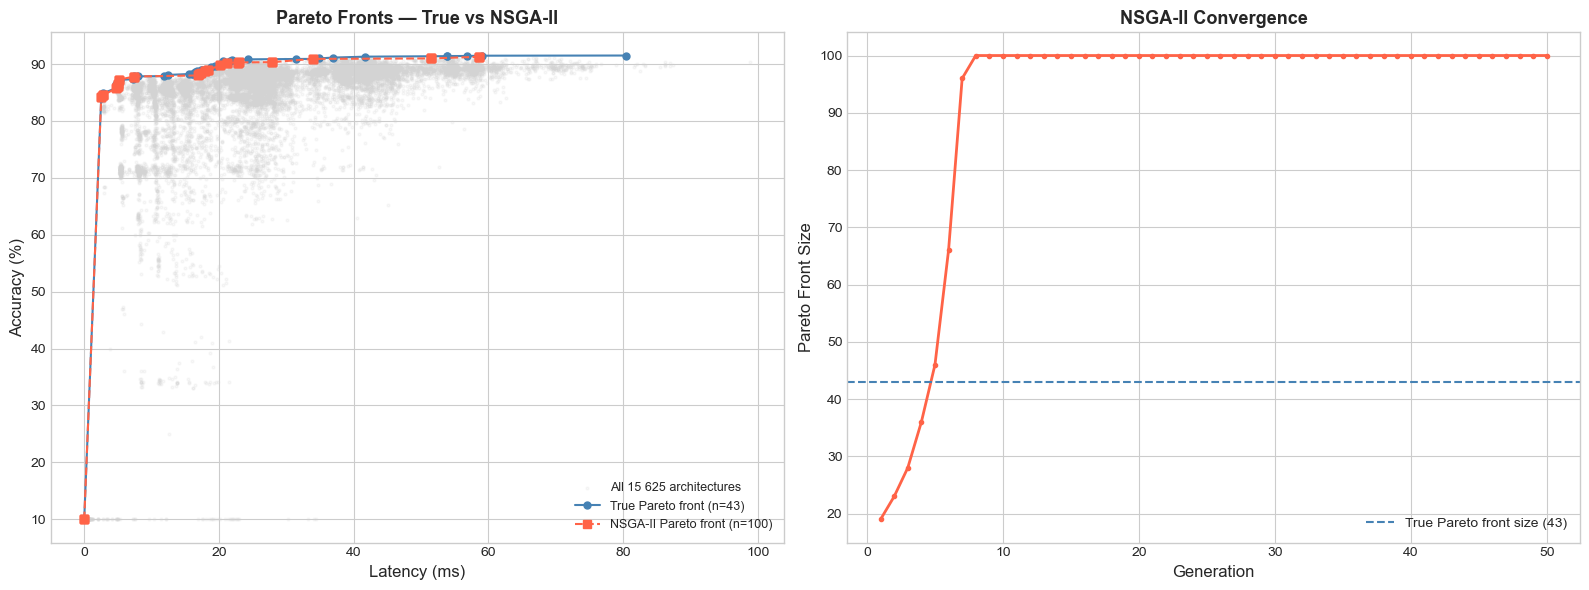

Figure saved as nsga2_pareto_comparison.png


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ── Panel A: Pareto fronts overlay ───────────────────────────────────────────
ax = axes[0]
ax.scatter(df_all["latency"], df_all["accuracy"],
           s=4, alpha=0.15, color="lightgray", label="All 15 625 architectures")

tp_sorted = true_pareto.sort_values("latency")
ax.plot(tp_sorted["latency"], tp_sorted["accuracy"],
        "o-", color="steelblue", markersize=5, linewidth=1.5,
        label=f"True Pareto front (n={len(true_pareto)})")

np_sorted = nsga2_pareto.sort_values("latency")
ax.plot(np_sorted["latency"], np_sorted["accuracy"],
        "s--", color="tomato", markersize=6, linewidth=1.5,
        label=f"NSGA-II Pareto front (n={len(nsga2_pareto)})")

ax.set_xlabel("Latency (ms)", fontsize=12)
ax.set_ylabel("Accuracy (%)", fontsize=12)
ax.set_title("Pareto Fronts — True vs NSGA-II", fontsize=13, fontweight="bold")
ax.legend(fontsize=9)

# ── Panel B: NSGA-II convergence ─────────────────────────────────────────────
ax2 = axes[1]
hist_df = pd.DataFrame(history)
ax2.plot(hist_df["generation"], hist_df["pareto_front_size"],
         color="tomato", linewidth=2, marker="o", markersize=3)
ax2.axhline(y=len(true_pareto), color="steelblue", linestyle="--",
            label=f"True Pareto front size ({len(true_pareto)})")
ax2.set_xlabel("Generation", fontsize=12)
ax2.set_ylabel("Pareto Front Size", fontsize=12)
ax2.set_title("NSGA-II Convergence", fontsize=13, fontweight="bold")
ax2.legend(fontsize=10)

plt.tight_layout()
plt.savefig("nsga2_pareto_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure saved as nsga2_pareto_comparison.png")

## 11 · NSGA-II Pareto front zoomed (low-latency region)

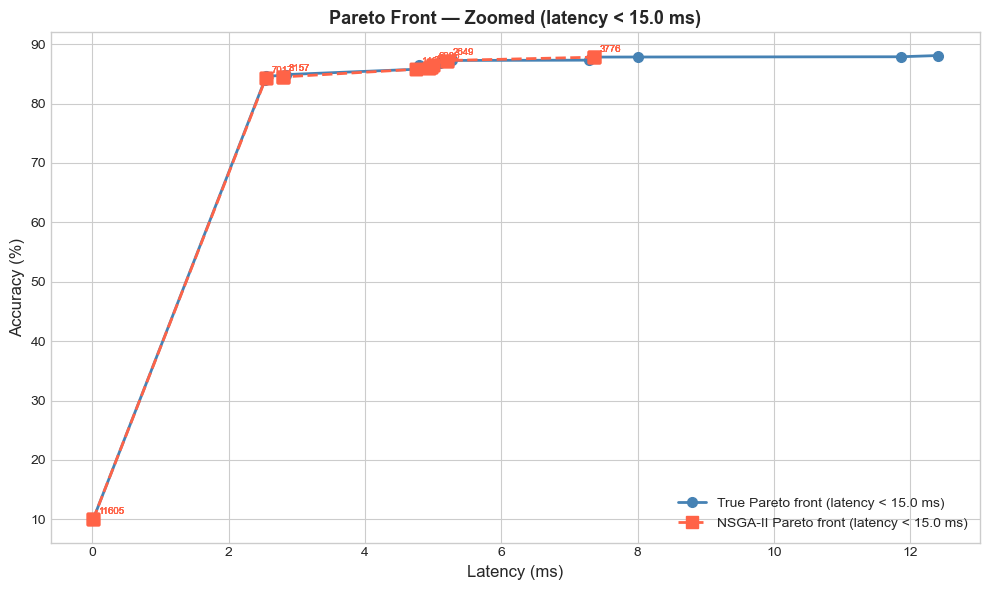

Figure saved as nsga2_pareto_zoomed.png


In [22]:
fig, ax = plt.subplots(figsize=(10, 6))

# Focus on the low-latency region (< 15 ms) — most practical for deployment
LAT_THRESH = 15.0

tp_zoom = true_pareto[true_pareto["latency"] < LAT_THRESH].sort_values("latency")
np_zoom = nsga2_pareto[nsga2_pareto["latency"] < LAT_THRESH].sort_values("latency")

ax.plot(tp_zoom["latency"], tp_zoom["accuracy"],
        "o-", color="steelblue", markersize=7, linewidth=2,
        label=f"True Pareto front (latency < {LAT_THRESH} ms)")

ax.plot(np_zoom["latency"], np_zoom["accuracy"],
        "s--", color="tomato", markersize=8, linewidth=2,
        label=f"NSGA-II Pareto front (latency < {LAT_THRESH} ms)")

# Annotate NSGA-II points
for _, row in np_zoom.iterrows():
    ax.annotate(f"{int(row['arch_index'])}",
                (row["latency"], row["accuracy"]),
                textcoords="offset points", xytext=(4, 4), fontsize=7, color="tomato")

ax.set_xlabel("Latency (ms)", fontsize=12)
ax.set_ylabel("Accuracy (%)", fontsize=12)
ax.set_title(f"Pareto Front — Zoomed (latency < {LAT_THRESH} ms)",
             fontsize=13, fontweight="bold")
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig("nsga2_pareto_zoomed.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure saved as nsga2_pareto_zoomed.png")

## 12 · Best architecture (distance to ideal point)

In [23]:
def normalize(x):
    return (x - x.min()) / (x.max() - x.min() + 1e-8)

df_nsga2["acc_norm"] = normalize(df_nsga2["accuracy"])
df_nsga2["lat_norm"] = normalize(df_nsga2["latency"])

ideal_acc = df_nsga2["acc_norm"].max()
ideal_lat = df_nsga2["lat_norm"].min()

df_nsga2["distance_to_ideal"] = np.sqrt(
    (df_nsga2["acc_norm"] - ideal_acc) ** 2 +
    (df_nsga2["lat_norm"] - ideal_lat) ** 2
)

best = df_nsga2.loc[df_nsga2["distance_to_ideal"].idxmin()]

print("\n BEST ARCHITECTURE — NSGA-II (Distance to Ideal Point)")
print(f"Index    : {int(best['arch_index'])}")
print(f"Accuracy : {best['accuracy']:.4f}%")
print(f"Latency  : {best['latency']:.4f} ms")
print(f"Distance : {best['distance_to_ideal']:.6f}")

print("\n Top 10 closest to ideal (NSGA-II population):")
display(df_nsga2.sort_values("distance_to_ideal").head(10)
        [["arch_index", "accuracy", "latency", "acc_norm", "lat_norm", "distance_to_ideal"]])


 BEST ARCHITECTURE — NSGA-II (Distance to Ideal Point)
Index    : 3157
Accuracy : 84.4800%
Latency  : 2.8023 ms
Distance : 0.096155

 Top 10 closest to ideal (NSGA-II population):


,arch_index,accuracy,latency,acc_norm,lat_norm,distance_to_ideal
15,3157,84.48,2.802269,0.916451,0.047597,0.096155
31,3157,84.48,2.802269,0.916451,0.047597,0.096155
54,3157,84.48,2.802269,0.916451,0.047597,0.096155
65,3157,84.48,2.802269,0.916451,0.047597,0.096155
80,3157,84.48,2.802269,0.916451,0.047597,0.096155
89,3157,84.48,2.802269,0.916451,0.047597,0.096155
45,7017,84.23,2.544041,0.913375,0.043193,0.096796
30,7017,84.23,2.544041,0.913375,0.043193,0.096796
95,7017,84.23,2.544041,0.913375,0.043193,0.096796
2,7017,84.23,2.544041,0.913375,0.043193,0.096796
